# Solutions to the exercises of Chapter 13

Sample solutions for [Chapter 13, View factors and enclosures](../../notebooks/part3_radiation/13_view_factors_enclosures.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq, fsolve

try:
    from engtransport import radiation, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import radiation, reference
from engtransport import convection_ext, natural_conv, properties
from engtransport.numerics import bisect
from engtransport.plotting import use_style

use_style()
SIGMA = radiation.SIGMA_SB

## Exercise 1. A blackbody reference

Treated as one surface of area $A_c$ (side wall and base) with uniform radiosity, the
cavity and its mouth $A_o$ form a two-surface enclosure (13.11) with the mouth black at
0 K and $F_{oc} = 1$, so $A_cF_{co} = A_o$. The radiation leaving the mouth, divided by
$A_o\sigma T^4$, is

$$
\varepsilon_a = \frac{\varepsilon}{\varepsilon + (1-\varepsilon)A_o/A_c} .
$$

The better model cuts the side wall into $n$ rings. All its view factors follow from the
disk formula (13.4): a ring between depths $z_1$ and $z_2$ sees the base with
$F_{base, ring} = F_{dd}(z_1) - F_{dd}(z_2)$, where $F_{dd}(h)$ is the factor between the
base and a disk at height $h$; and two rings exchange through the exchange area $G(h)$ of
a wall section of height $h$ with itself, $G(h) = 2\pi R h - 2\pi R^2[1 - F_{dd}(h)]$, as
in `radiation.box_zone_view_factors`. Ray tracing (`reference.mc_cylinder_cavity`) checks
both.

depth 0.25 D: one zone 0.9474; rings: mouth 0.9450, base 0.9374
depth 0.50 D: one zone 0.9643; rings: mouth 0.9623, base 0.9599
depth 1.00 D: one zone 0.9783; rings: mouth 0.9721, base 0.9815
depth 1.50 D: one zone 0.9844; rings: mouth 0.9741, base 0.9901
depth 2.00 D: one zone 0.9878; rings: mouth 0.9747, base 0.9940
depth 3.00 D: one zone 0.9915; rings: mouth 0.9749, base 0.9972
depth 4.00 D: one zone 0.9935; rings: mouth 0.9750, base 0.9984
depth 6.00 D: one zone 0.9956; rings: mouth 0.9750, base 0.9993
ray tracing at 0.5, 1, 2 and 6 D: 0.9622 +- 0.0002, 0.9722 +- 0.0002, 0.9748 +- 0.0002, 0.9752 +- 0.0002


the base reaches an apparent emissivity of 0.99 at a depth of 1.49 diameters


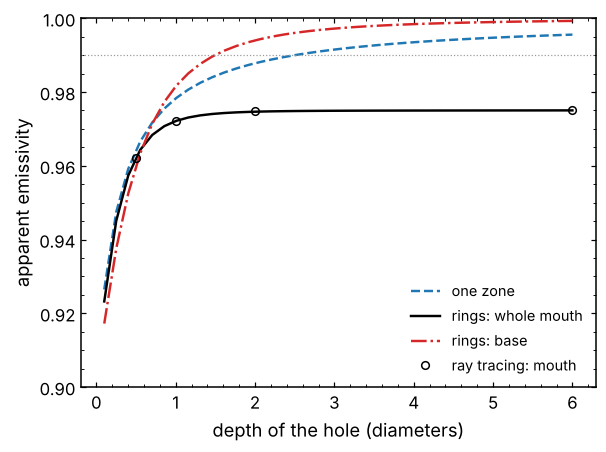

In [2]:
def cavity(depth, R, eps, n=160):
    """Isothermal cylindrical cavity: base, n rings, black mouth at 0 K.

    Returns the apparent emissivity of the mouth and the mean radiosity of the base over
    sigma T^4 (what a camera looking at the base sees).
    """
    A_d = math.pi * R * R
    F_dd = lambda h: 1.0 if h <= 0 else radiation.view_factor_coaxial_disks(R, R, h)
    G = lambda h: 0.0 if h == 0 else 2 * math.pi * R * abs(h) - 2 * A_d * (1 - F_dd(abs(h)))
    z = np.linspace(0.0, depth, n + 1)
    N = n + 2                                   # 0 base, 1..n rings, n+1 mouth
    AF = np.zeros((N, N))
    A = np.empty(N)
    A[0] = A[-1] = A_d
    A[1:-1] = 2 * math.pi * R * np.diff(z)
    AF[0, -1] = AF[-1, 0] = A_d * F_dd(depth)
    for k in range(n):
        AF[0, k + 1] = AF[k + 1, 0] = A_d * (F_dd(z[k]) - F_dd(z[k + 1]))
        AF[-1, k + 1] = AF[k + 1, -1] = A_d * (F_dd(depth - z[k + 1]) - F_dd(depth - z[k]))
        for m in range(n):
            AF[k + 1, m + 1] = 0.5 * (G(z[k + 1] - z[m]) + G(z[k] - z[m + 1]) - G(z[k + 1] - z[m + 1]) - G(z[k] - z[m]))
    F = AF / A[:, None]
    e = np.full(N, eps)
    e[-1] = 1.0
    T = np.full(N, 1000.0)
    T[-1] = 0.0
    s = radiation.solve_radiosity_enclosure(A, e, F, T)
    Eb = SIGMA * 1000.0**4
    return -s["Q"][-1] / (A_d * Eb), s["J"][0] / Eb


eps, R = 0.9, 0.5                                   # diameter 1: depth in diameters
LD = np.array([0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0])
one_zone = eps / (eps + (1 - eps) * (math.pi * R**2) / (math.pi * R**2 + 2 * math.pi * R * LD))
rings = np.array([cavity(L, R, eps) for L in LD])
mc = np.array([reference.mc_cylinder_cavity(L, R, eps, 1_000_000, seed=5) for L in LD[[1, 2, 4, 7]]])
for L, a, (m, b) in zip(LD, one_zone, rings):
    print(f"depth {L:4.2f} D: one zone {a:.4f}; rings: mouth {m:.4f}, base {b:.4f}")
print("ray tracing at 0.5, 1, 2 and 6 D: " + ", ".join(f"{f:.4f} +- {s:.4f}" for f, s in mc))
LD_99 = brentq(lambda L: cavity(L, R, eps)[1] - 0.99, 0.5, 4.0, xtol=1e-4)
print(f"the base reaches an apparent emissivity of 0.99 at a depth of {LD_99:.2f} diameters")

LD_f = np.linspace(0.1, 6.0, 40)
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(LD_f, eps / (eps + (1 - eps) * R / (R + 2 * LD_f)), "C0--", label="one zone")
ax.plot(LD_f, [cavity(L, R, eps, 80)[0] for L in LD_f], "k-", label="rings: whole mouth")
ax.plot(LD_f, [cavity(L, R, eps, 80)[1] for L in LD_f], "C3-.", label="rings: base")
ax.plot(LD[[1, 2, 4, 7]], mc[:, 0], "ko", ms=5, mfc="none", label="ray tracing: mouth")
ax.axhline(0.99, color="0.6", ls=":", lw=0.8)
ax.set_xlabel("depth of the hole (diameters)")
ax.set_ylabel("apparent emissivity")
ax.set_ylim(0.9, 1.0)
ax.legend(loc="lower right")
plt.show()

**Figure S13.1.** Apparent emissivity of a cylindrical hole with $\varepsilon = 0.9$
against its depth: one-zone model, ring model for the whole mouth and for the base, and
ray tracing.

The one-zone model says that a deeper hole always gets closer to black, approaching 0.996
at six diameters. The ring model and ray tracing agree with each other to $2\times10^{-4}$
and show something else: the mouth as a whole never exceeds 0.975. Radiation that leaves
the mouth at a slant comes from the side wall near the opening, which sees the cold
outside and has a radiosity well below $\sigma T^4$ however deep the hole is. A camera that
looks straight at the base sees much better: the base as a whole reaches 0.99 at a depth of
1.5 diameters. Sparrow, Albers and Eckert (1962), who solved the integral equations of the
same problem, found 1.6 diameters for the centre of the base, which sees the most of the
opening. A reference cavity must therefore be viewed along its axis and filled by the
camera's field of view from the base, and the uniform-radiosity assumption fails exactly
where it matters.

## Exercise 2. A thermocouple in a hot duct

The bare probe balances convection from the air against radiation to the walls,
$h(T_g - T_p) = \varepsilon\sigma(T_p^4 - T_w^4)$. With a shield, the probe radiates to the
shield as long concentric cylinders (13.11), and the shield takes heat by convection on
both faces and from the probe, and radiates to the walls.

In [3]:
T_gas, T_wall, V = 773.15, 573.15, 8.0
d_p, eps_p = 3e-3, 0.8


def h_cyl(D, T_s):
    p = properties.dry_air_properties(0.5 * (T_s + T_gas))
    return convection_ext.nu_cylinder_churchill_bernstein(V * D / p["nu"], p["Pr"]) * p["k"] / D


T_bare = brentq(lambda T: h_cyl(d_p, T) * (T_gas - T) - eps_p * SIGMA * (T**4 - T_wall**4), T_wall, T_gas)
print(f"bare probe: reads {T_bare - 273.15:.1f} C, {T_gas - T_bare:.1f} K low (h = {h_cyl(d_p, T_bare):.0f} W/(m2 K))")
D_s = 12e-3
for eps_s in (0.3, 0.1):
    def balance(x):
        T, T_s = x
        q_ps = SIGMA * (T**4 - T_s**4) / (1 / eps_p + (d_p / D_s) * (1 / eps_s - 1))     # per m2 of probe
        probe = h_cyl(d_p, T) * (T_gas - T) - q_ps
        shield = (2 * h_cyl(D_s, T_s) * (T_gas - T_s) * math.pi * D_s + q_ps * math.pi * d_p
                  - eps_s * SIGMA * (T_s**4 - T_wall**4) * math.pi * D_s)
        return [probe / 1e3, shield / 1e3]
    T_p, T_s = fsolve(balance, [T_gas - 20, T_gas - 40], xtol=1e-12)
    print(f"shield eps {eps_s}: probe reads {T_p - 273.15:.1f} C ({T_gas - T_p:.1f} K low), shield at {T_s - 273.15:.1f} C")

bare probe: reads 453.0 C, 47.0 K low (h = 164 W/(m2 K))
shield eps 0.3: probe reads 494.8 C (5.2 K low), shield at 479.2 C
shield eps 0.1: probe reads 498.8 C (1.2 K low), shield at 492.2 C


The bare probe reads 453 °C, 47 K below the air: its convection coefficient of
164 W/(m² K) cannot outweigh radiation to walls 200 K cooler. A shield with
$\varepsilon = 0.3$, itself at 479 °C, cuts the error to 5.2 K, and a polished one with
$\varepsilon = 0.1$ to 1.2 K. The shield works twice: it replaces the cold walls in the
probe's view by a surface close to the air temperature, and its own low emissivity keeps
it there. The model assumes that the air flows through the shield as fast as outside it;
real shields are open-ended tubes aligned with the flow, or the probe is aspirated, so that
this holds.

## Exercise 3. Opening the door

Before the door opens, the furnace is in the state of Section 13.4 with the heater at
1000 °C and the load at 850 °C. The walls hold a lot of heat, and in 30 s their surface
hardly cools, so they are kept at their closed-door temperature. The door (the face
$y = 0$) is then a black surface at 25 °C in the six-face enclosure.

In [4]:
Lx, Ly, Lz = 0.8, 1.2, 0.6
A6, F6 = radiation.box_view_factors(Lx, Ly, Lz)
A3 = np.array([A6[1], A6[0], A6[2:].sum()])
F3 = np.zeros((3, 3))
F3[0, 1], F3[1, 0] = F6[1, 0], F6[0, 1]
F3[0, 2], F3[1, 2] = 1 - F3[0, 1], 1 - F3[1, 0]
F3[2, :2] = A3[:2] * F3[:2, 2] / A3[2]
F3[2, 2] = 1 - F3[2, 0] - F3[2, 1]
T_h, T_l, T_room, R_wall = 1273.15, 1123.15, 298.15, 1.10


def closed(T_w):
    return radiation.solve_radiosity_enclosure(A3, [0.7, 0.8, 0.5], F3, [T_h, T_l, T_w])


T_w = bisect(lambda T: -closed(T)["Q"][2] - A3[2] * (T - T_room) / R_wall, T_room, 2500.0)[0]
c = closed(T_w)
print(f"door closed: heater {c['Q'][0] / 1e3:.1f} kW, load takes {-c['Q'][1] / 1e3:.1f} kW, walls at {T_w - 273.15:.0f} C")
eps6 = np.array([0.8, 0.7, 0.5, 0.5, 1.0, 0.5])               # floor, roof, x=0, x=Lx, door, y=Ly
o = radiation.solve_radiosity_enclosure(A6, eps6, F6, [T_l, T_h, T_w, T_w, T_room, T_w])
walls = o["Q"][[2, 3, 5]].sum()
print(f"door open: through the door {-o['Q'][4] / 1e3:.1f} kW; heater {o['Q'][1] / 1e3:.1f} kW; "
      f"walls give up {walls / 1e3:.1f} kW; load takes {-o['Q'][0] / 1e3:.1f} kW")
lost = (c["Q"][1] - o["Q"][0]) * 30.0
print(f"in 30 s: {-o['Q'][4] * 30 / 1e6:.2f} MJ leaves; the load misses {-lost / 1e3:.0f} kJ "
      f"= {-lost / -c['Q'][1]:.0f} s of heating ({-lost / (300 * 600):.1f} K)")

door closed: heater 26.9 kW, load takes 24.9 kW, walls at 919 C
door open: through the door 51.8 kW; heater 41.5 kW; walls give up 17.9 kW; load takes 7.7 kW
in 30 s: 1.55 MJ leaves; the load misses 518 kJ = 21 s of heating (2.9 K)


With the door closed and the load at 850 °C, the heater gives 26.9 kW and the load takes
24.9 kW. Opened, the door swallows 51.8 kW, as much as a black body at about
$(51.8\ \mathrm{kW}/(0.48\ \mathrm{m^2}\,\sigma))^{1/4}$ ≈ 1170 K: the opening sees mostly
hot surfaces. The heater has to supply 41.5 kW, slightly above the installed 40 kW, the
walls give up 17.9 kW from their stored heat, and the load's share falls to 7.7 kW. The
load does not cool; it just heats more slowly. Over 30 s it misses 518 kJ, 21 s of heating
or 2.9 K; the walls, which cool by giving up stored heat, take longer to recover.

## Exercise 4. Inside the electronics cabinet

The equipment (1) inside the cabinet walls (2) is a two-surface enclosure with
$F_{12} = 1$. Its other path is natural convection to the inside air and from the air to
the walls, each with the Churchill–Chu coefficient for a vertical plate as high as the
surface: a rough model of the flow in a closed box.

In [5]:
A1 = 4 * 1.2 * 0.4 + 2 * 0.4 * 0.4
A2 = 4 * 1.6 * 0.6 + 2 * 0.6 * 0.6
T2, P = 323.15, 623.0


def h_nat(Ta, Tb, L):
    p = properties.dry_air_properties(0.5 * (Ta + Tb))
    Ra = 9.81 * p["beta"] * abs(Ta - Tb) * L**3 / (p["nu"] * p["alpha"])
    return natural_conv.nu_vertical_plate_churchill_chu(Ra, p["Pr"]) * p["k"] / L


for eps2 in (0.9, 0.25):
    q_rad = lambda T1: SIGMA * A1 * (T1**4 - T2**4) / (1 / 0.9 + A1 / A2 * (1 / eps2 - 1))     # Eq. (13.11)

    def balance(x):
        T1, Ta = x
        q_conv = h_nat(T1, Ta, 1.2) * A1 * (T1 - Ta)
        return [q_rad(T1) + q_conv - P, q_conv - h_nat(Ta, T2, 1.6) * A2 * (Ta - T2)]
    T1, Ta = fsolve(balance, [350.0, 335.0], xtol=1e-12)
    print(f"walls inside eps {eps2}: equipment {T1 - 273.15:.1f} C, inside air {Ta - 273.15:.1f} C, "
          f"radiation {q_rad(T1):.0f} W ({100 * q_rad(T1) / P:.0f} %)")

walls inside eps 0.9: equipment 78.7 C, inside air 60.5 C, radiation 481 W (77 %)
walls inside eps 0.25: equipment 95.3 C, inside air 66.5 C, radiation 369 W (59 %)


With painted walls the equipment surface runs at 78.7 °C, 29 K above the walls, and
radiation carries 77 % of the 623 W; the inside air settles at 60.5 °C. Inside bare
galvanised walls, radiation carries only 59 %, and the equipment runs 17 K hotter, at
95.3 °C. Painting the inside of a cabinet black or white (both have $\varepsilon \approx
0.9$ in the infrared) is as effective as a much larger cabinet. These are surface
temperatures; the components inside the equipment run hotter still, by an amount set by
its own internal design. This completes the estimate that Chapter 9 left open: the 50 °C
wall limit corresponds to an equipment surface near 79 °C with painted walls and 95 °C
with bare ones, and whether that is acceptable depends on the components.